# Chapter 2 - Data and Sampling Distributions

**Practical Statistics for Data Scientists, 2nd ed.** - Peter Bruce, Andrew Bruce, and Peter Gedeck

This notebook uses original, offline data to demonstrate sampling variation, selection bias, the bootstrap, confidence intervals, and common probability distributions.

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
rng = np.random.default_rng(42)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

## 1. Population, random sampling, and bias

A **population** is the full group of interest; a **sample** is what we observe. A random sample can differ from the population through chance. **Selection bias** is different: the sampling mechanism systematically excludes or overrepresents a group. Increasing a biased sample's size only estimates the wrong target more precisely.

In [2]:
population = pd.DataFrame({
    "age": rng.integers(18, 81, 100_000),
    "annual_value": np.exp(rng.normal(4.1, .75, 100_000)),
})
random_sample = population.sample(400, random_state=42)
biased_sample = population.query("age < 35").sample(400, random_state=42)
pd.Series({"population mean": population.annual_value.mean(),
           "random sample mean": random_sample.annual_value.mean(),
           "biased sample mean": biased_sample.annual_value.mean(),
           "random sample mean age": random_sample.age.mean(),
           "biased sample mean age": biased_sample.age.mean()}).round(2)

population mean           79.96
random sample mean        82.88
biased sample mean        80.30
random sample mean age    49.20
biased sample mean age    25.86
dtype: float64

## 2. Sampling distributions, CLT, and standard error

Repeat a sampling procedure and the resulting statistic (for example, the mean) has a **sampling distribution**. The central limit theorem says that many sample means become approximately normal as sample size grows, even if individual values are skewed. The standard error is the standard deviation of that sampling distribution; for a mean it is commonly estimated as $s/\sqrt{n}$.

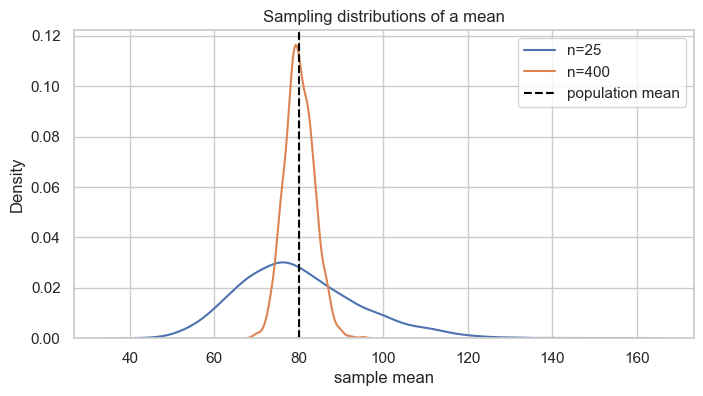

SE from repeated samples (n=25)     14.356
SE from repeated samples (n=400)     3.515
estimated SE (n=400)                 3.199
dtype: float64

In [3]:
def repeated_means(values, sample_size, repetitions=2000, seed=7):
    local_rng = np.random.default_rng(seed)
    return np.array([local_rng.choice(values, sample_size, replace=False).mean() for _ in range(repetitions)])

means_25 = repeated_means(population.annual_value.to_numpy(), 25)
means_400 = repeated_means(population.annual_value.to_numpy(), 400)
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(means_25, label="n=25", ax=ax); sns.kdeplot(means_400, label="n=400", ax=ax)
ax.axvline(population.annual_value.mean(), color="black", ls="--", label="population mean")
ax.set(title="Sampling distributions of a mean", xlabel="sample mean"); ax.legend(); plt.show()
pd.Series({"SE from repeated samples (n=25)": means_25.std(ddof=1),
           "SE from repeated samples (n=400)": means_400.std(ddof=1),
           "estimated SE (n=400)": random_sample.annual_value.std(ddof=1)/np.sqrt(400)}).round(3)

## 3. Bootstrap and confidence intervals

The **bootstrap** resamples an observed sample *with replacement*. The distribution of bootstrapped statistics approximates sampling uncertainty if the original sample represents the target population. A 95% percentile interval is created by a repeated procedure that covers the fixed population parameter about 95% of the time in long runs; it is not a 95% probability statement about the already calculated endpoints.

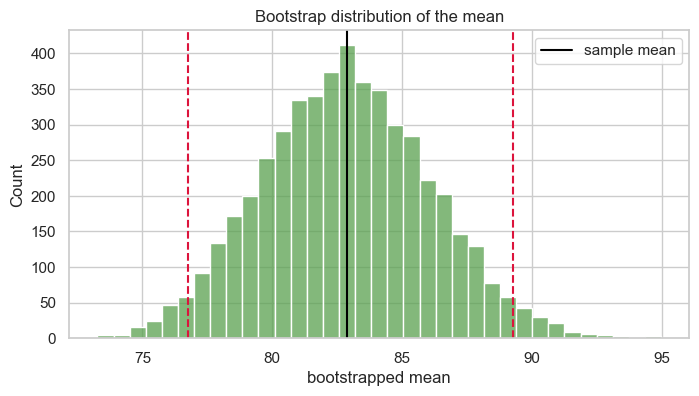

95% percentile interval: (76.76, 89.25)


In [ ]:
def bootstrap_statistic(values, repetitions=5000, seed=10):
    local_rng = np.random.default_rng(seed); values = np.asarray(values)
    return np.array([local_rng.choice(values, len(values), replace=True).mean() for _ in range(repetitions)])

boot_means = bootstrap_statistic(random_sample.annual_value)
lo, hi = np.quantile(boot_means, [.025, .975])
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(boot_means, bins=35, color="#59a14f", ax=ax)
ax.axvline(lo, color="crimson", ls="--"); ax.axvline(hi, color="crimson", ls="--")
ax.axvline(random_sample.annual_value.mean(), color="black", label="sample mean")
ax.set(title="Bootstrap distribution of the mean", xlabel="bootstrapped mean"); ax.legend(); plt.show()
print(f"95% percentile interval: ({lo:.2f}, {hi:.2f})")

## 4. Distributional models

The normal distribution is a reference model for many averages. The t distribution has heavier tails, reflecting extra uncertainty when a population standard deviation is estimated from small samples. A QQ plot compares data quantiles with a normal reference. Binomial models count successes in fixed trials, Poisson models count events at a stable rate, exponential models describe constant-rate waiting time, and Weibull models allow the event rate to change over time.

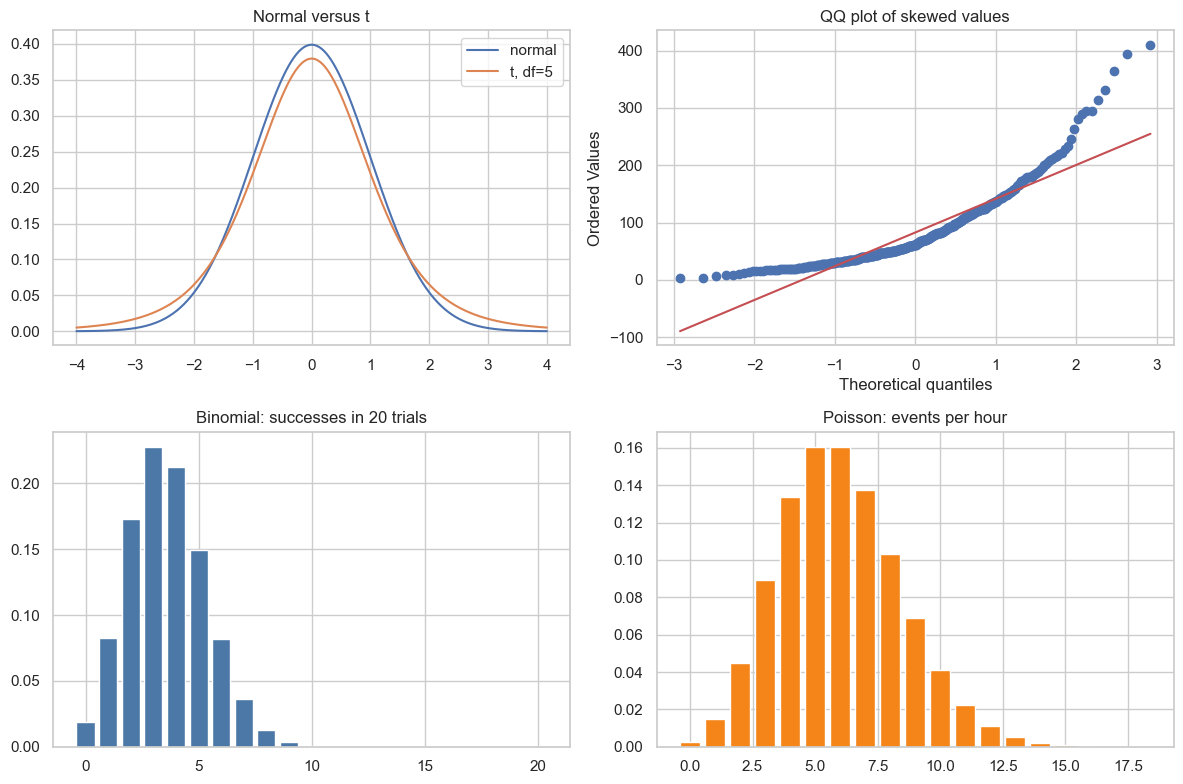

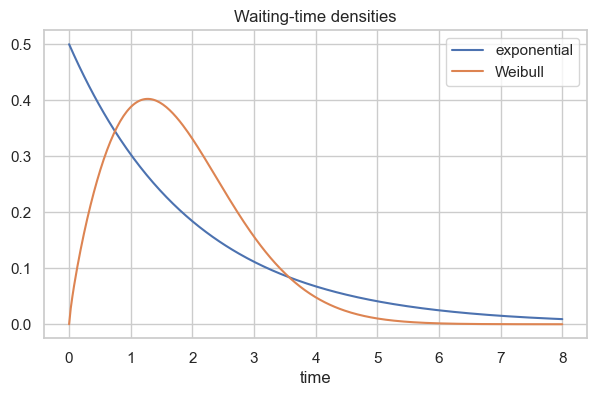

In [5]:
from scipy import stats
from scipy.stats import binom, poisson, expon, weibull_min
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
x = np.linspace(-4, 4, 400)
axes[0,0].plot(x, stats.norm.pdf(x), label="normal"); axes[0,0].plot(x, stats.t.pdf(x, 5), label="t, df=5")
axes[0,0].set_title("Normal versus t"); axes[0,0].legend()
stats.probplot(random_sample.annual_value, dist="norm", plot=axes[0,1]); axes[0,1].set_title("QQ plot of skewed values")
k = np.arange(21); axes[1,0].bar(k, binom.pmf(k, 20, .18), color="#4c78a8"); axes[1,0].set_title("Binomial: successes in 20 trials")
k = np.arange(19); axes[1,1].bar(k, poisson.pmf(k, 6), color="#f58518"); axes[1,1].set_title("Poisson: events per hour")
plt.tight_layout()
t = np.linspace(0, 8, 300)
plt.figure(figsize=(7, 4)); plt.plot(t, expon.pdf(t, scale=2), label="exponential"); plt.plot(t, weibull_min.pdf(t, 1.8, scale=2), label="Weibull")
plt.title("Waiting-time densities"); plt.xlabel("time"); plt.legend(); plt.show()

## Chapter 2 summary

- Random error is expected; selection bias is a systematic error that size alone cannot repair.
- Bigger random samples usually make sampling distributions narrower, reducing standard error.
- Bootstrap resampling exposes the uncertainty in a sample statistic without a closed-form formula.
- Probability models are useful approximations whose assumptions should be checked.

**Reference:** Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists* (2nd ed.), Chapter 2. Concepts and organization informed by the supplied PDF; all prose, code, and synthetic data here are original.